# 01b — CSE-CIC-IDS2018 Extended Exploratory Data Analysis

## Purpose and relationship to the primary EDA

This companion notebook performs the detailed, 2018-only analysis that was previously embedded in `01_eda.ipynb`. It supports the project goal of understanding CSE-CIC-IDS2018 before using it as an external test dataset for a detector trained on CICIDS2017.

The primary notebook retains the CICIDS2017 EDA and cross-year distribution comparisons. This notebook focuses on full-data quality, anomalies, protocols, ports, sampled distributions, attack timing, class behavior, feature redundancy, and PCA for CSE-CIC-IDS2018.


In [1]:
import glob, json, os, warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from scipy.spatial.distance import squareform
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)
pd.set_option('display.max_rows', 120)
pd.set_option('display.max_columns', 40)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'grid.color': '#e6e6e3', 'axes.edgecolor': '#9a9993',
                     'axes.titleweight': 'bold', 'figure.dpi': 100})

BLUE, ORANGE, GREY = '#2a78d6', '#eb6834', '#9a9993'
ROOT = './Data/archive'
D17, D18 = f'{ROOT}/CICIDS2017_improved', f'{ROOT}/CSECICIDS2018_improved'
SAMPLE18 = './Data/sample_2018_stratified.csv.gz'
SEED = 0
ID_COLS = ['id', 'Flow ID', 'Src IP', 'Src Port', 'Dst IP', 'Timestamp', 'Attempted Category']

def signed_log(values):
    return np.sign(values) * np.log1p(np.abs(values))

files17 = sorted(glob.glob(f'{D17}/*.csv'))
files18 = sorted(glob.glob(f'{D18}/*.csv'))
if not files18:
    raise FileNotFoundError(f'No CSE-CIC-IDS2018 CSV files found under {D18}')

cols18 = pd.read_csv(files18[0], nrows=5).columns
cols17 = pd.read_csv(files17[0], nrows=5).columns if files17 else pd.Index([])
print(f'2018 source files: {len(files18)} | columns: {len(cols18)}')
print(f'Schema matches CICIDS2017: {bool(files17) and list(cols17) == list(cols18)}')

/Users/ranga/.matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /var/folders/8p/7ywd43m12fz07p58l3312vqh0000gn/T/matplotlib-9jhy8_5e because there was an issue with the default path (/Users/ranga/.matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.



Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/ranga/.cache/fontconfig
	/Users/ranga/.fontconfig


Matplotlib is building the font cache; this may take a moment.


2018 source files: 10 | columns: 91
Schema matches CICIDS2017: True


## Prepare the stratified 2018 analysis sample

**Why we are doing this.** A reusable per-label sample is prepared for computationally intensive plots while the full files remain available for exact streamed counts.

**Business relevance.** Sampling keeps the analysis reproducible and affordable and preserves visibility into rare attacks, but it must not be used to estimate real-world prevalence.

The full dataset is approximately 36 GB, so distribution-heavy visualizations use a cached per-label sample. The full-data audit below still uses exact streamed counts. Because the sample deliberately retains many observations from rare labels, its class proportions must not be interpreted as population prevalence.


In [2]:
use_columns = [c for c in cols18 if c not in ('Flow ID', 'Src IP', 'Dst IP')]
dtypes18 = {c: 'int64' for c in ('id', 'Src Port', 'Dst Port', 'Protocol', 'Attempted Category')}

if not os.path.exists(SAMPLE18):
    per_attack, benign = 20_000, 200_000
    rng = np.random.default_rng(SEED)
    retained = {}
    for file_name in files18:
        for chunk in pd.read_csv(file_name, usecols=use_columns, dtype=dtypes18, chunksize=150_000):
            chunk['_sample_key'] = rng.random(len(chunk))
            for label, group in chunk.groupby('Label'):
                limit = benign if label == 'BENIGN' else per_attack
                group = group if label not in retained else pd.concat([retained[label], group])
                retained[label] = group.nsmallest(limit, '_sample_key') if len(group) > limit else group
    pd.concat(retained.values()).drop(columns='_sample_key').to_csv(
        SAMPLE18, index=False, compression='gzip'
    )

s18 = pd.read_csv(SAMPLE18)
feature_candidates = [c for c in cols18 if c not in ID_COLS + ['Label']]
finite_sample = s18[feature_candidates].replace([np.inf, -np.inf], np.nan)
constant_features = [c for c in feature_candidates if finite_sample[c].nunique(dropna=True) <= 1]
FEATURES = [c for c in feature_candidates if c not in constant_features]
fill_values18 = finite_sample[FEATURES].max().fillna(0)
s18[FEATURES] = finite_sample[FEATURES].fillna(fill_values18)

print(f'2018 stratified sample: {len(s18):,} flows across {s18.Label.nunique()} labels')
print(f'Analysis features: {len(FEATURES)} | constant sample features removed: {constant_features}')
display(s18['Label'].value_counts().rename('sample flows').to_frame())

2018 stratified sample: 378,952 flows across 25 labels
Analysis features: 82 | constant sample features removed: ['Bwd URG Flags']


,sample flows
Label,
BENIGN,200000
Botnet Ares,20000
SSH-BruteForce,20000
DDoS-LOIC-HTTP,20000
DoS GoldenEye,20000
Infiltration - NMAP Portscan,20000
DDoS-HOIC,20000
FTP-BruteForce - Attempted,20000
DoS Hulk,20000


### Sample-preparation takeaway

The cached stratified sample contains 378,952 flows across 25 labels and makes rare-class analysis practical. It intentionally changes the class mixture, so all prevalence and volume statements continue to use full-data streamed counts.


## Analysis roadmap

Two levels of analysis are used:

1. **Full-data streaming audit:** all 63.2 million rows are scanned in chunks to measure missing and infinite values, anomalies, protocol counts, destination-port counts, and file coverage. Results are cached so later runs do not rescan approximately 36 GB.
2. **Stratified-sample analysis:** the cached per-label sample is used for distribution plots, outlier screening, correlation, redundancy clustering, PCA, and attack timing. Sample class proportions are not interpreted as population prevalence.


### 2018.1 Full-data quality, anomaly, protocol, and port audit

**Why we are doing this.** Every 2018 CSV is audited in chunks for coverage, missing and infinite values, invalid measurements, protocols, and destination ports; summaries are cached for later runs.

**Business relevance.** An exact audit prevents silent data-quality failures and provides population-level evidence without requiring all 63.2 million rows in memory.

The scan below is exact for counts. The first run can take several minutes; subsequent runs load the cached summaries.


In [3]:
import json
from collections import Counter
from pathlib import Path

CACHE18_DIR = Path('./Data/eda2018_stream_cache')
CACHE18_DIR.mkdir(parents=True, exist_ok=True)
QUALITY18_CACHE = CACHE18_DIR / 'quality.json'
PROTOCOL18_CACHE = CACHE18_DIR / 'protocol_counts.csv'
PORT18_CACHE = CACHE18_DIR / 'port_counts.csv'
FILE18_CACHE = CACHE18_DIR / 'file_rows.csv'

if all(p.exists() for p in [QUALITY18_CACHE, PROTOCOL18_CACHE, PORT18_CACHE, FILE18_CACHE]):
    quality18 = json.loads(QUALITY18_CACHE.read_text())
    protocol18 = pd.read_csv(PROTOCOL18_CACHE)
    ports18 = pd.read_csv(PORT18_CACHE)
    file_rows18 = pd.read_csv(FILE18_CACHE)
    print('Loaded cached full-data 2018 EDA summaries.')
else:
    missing_counts = Counter()
    infinite_counts = Counter()
    protocol_counts = Counter()
    port_counts = Counter()
    file_rows = []
    anomaly_counts = Counter()
    total_rows = 0

    for file_name in sorted(glob.glob(f'{D18}/*.csv')):
        rows_in_file = 0
        for chunk in pd.read_csv(file_name, chunksize=250_000):
            n = len(chunk)
            rows_in_file += n
            total_rows += n
            missing_counts.update(chunk.isna().sum().astype(int).to_dict())

            numeric = chunk.select_dtypes(include='number')
            infinite_counts.update(np.isinf(numeric).sum().astype(int).to_dict())

            protocol_counts.update(
                {(str(label), int(protocol)): int(count)
                 for (label, protocol), count in chunk.groupby(['Label', 'Protocol']).size().items()}
            )
            port_counts.update(
                {(str(label), int(port)): int(count)
                 for (label, port), count in chunk.groupby(['Label', 'Dst Port']).size().items()}
            )

            anomaly_counts['zero or negative duration'] += int((chunk['Flow Duration'] <= 0).sum())
            anomaly_counts['negative forward header length'] += int((chunk['Fwd Header Length'] < 0).sum())
            anomaly_counts['negative backward header length'] += int((chunk['Bwd Header Length'] < 0).sum())
            anomaly_counts['infinite flow byte rate'] += int(np.isinf(chunk['Flow Bytes/s']).sum())
            anomaly_counts['infinite flow packet rate'] += int(np.isinf(chunk['Flow Packets/s']).sum())

        file_rows.append({'file': os.path.basename(file_name), 'rows': rows_in_file})
        print(f'scanned {os.path.basename(file_name)}: {rows_in_file:,} rows')

    quality18 = {
        'total_rows': total_rows,
        'missing_counts': dict(missing_counts),
        'infinite_counts': dict(infinite_counts),
        'anomaly_counts': dict(anomaly_counts),
    }
    protocol18 = pd.DataFrame([
        {'Label': key[0], 'Protocol': key[1], 'flows': value}
        for key, value in protocol_counts.items()
    ])
    ports18 = pd.DataFrame([
        {'Label': key[0], 'Dst Port': key[1], 'flows': value}
        for key, value in port_counts.items()
    ])
    file_rows18 = pd.DataFrame(file_rows)
    QUALITY18_CACHE.write_text(json.dumps(quality18, indent=2))
    protocol18.to_csv(PROTOCOL18_CACHE, index=False)
    ports18.to_csv(PORT18_CACHE, index=False)
    file_rows18.to_csv(FILE18_CACHE, index=False)

missing18 = pd.Series(quality18['missing_counts'], dtype='int64')
infinite18 = pd.Series(quality18['infinite_counts'], dtype='int64')
anomalies18 = pd.Series(quality18['anomaly_counts'], name='rows')

print(f"Full 2018 rows audited: {quality18['total_rows']:,}")
print('Columns with missing values:', missing18[missing18 > 0].to_dict())
print('Columns with infinite values:', infinite18[infinite18 > 0].to_dict())
display(file_rows18)
display(anomalies18.to_frame())

Loaded cached full-data 2018 EDA summaries.
Full 2018 rows audited: 63,195,145
Columns with missing values: {}
Columns with infinite values: {'Flow Bytes/s': 57, 'Flow Packets/s': 57}


,file,rows
0,Friday-02-03-2018.csv,6311371
1,Friday-16-02-2018.csv,7390266
2,Friday-23-02-2018.csv,5976481
3,Thursday-01-03-2018.csv,6551401
4,Thursday-15-02-2018.csv,5410102
5,Thursday-22-02-2018.csv,6071153
6,Tuesday-20-02-2018.csv,6054702
7,Wednesday-14-02-2018.csv,5898350
8,Wednesday-21-02-2018.csv,6962593
9,Wednesday-28-02-2018.csv,6568726


,rows
zero or negative duration,57
negative forward header length,10039
negative backward header length,17509
infinite flow byte rate,57
infinite flow packet rate,57


#### 2018.1 takeaway

The audit covers 63,195,145 rows across all ten source files. It finds no missing cells, but identifies 57 infinite byte-rate and packet-rate values plus negative forward and backward header lengths. These known anomalies require explicit preprocessing before modeling.


### 2018.2 Protocol and destination-port characteristics

**Why we are doing this.** Exact full-population counts are used to examine which protocols and services appear in effective attacks.

**Business relevance.** Protocol and port patterns can support triage, but they may encode the research network's service layout. Cross-network testing is required before treating them as durable attack indicators.

These tables and plots use exact counts from the full streamed dataset, not the stratified sample.


Protocol,0,1,6,17
Label,,,,
BENIGN,77810,105540,34213841,24956295
Botnet Ares,0,0,142921,0
Botnet Ares - Attempted,0,0,262,0
DDoS-HOIC,0,0,1082293,0
DDoS-LOIC-HTTP,0,0,289328,0
DDoS-LOIC-UDP,0,0,0,2527
DDoS-LOIC-UDP - Attempted,0,251,0,0
DoS GoldenEye,0,0,22560,0
DoS GoldenEye - Attempted,0,0,4301,0


,top 3 destination ports
Label,
BENIGN,"53 (24,440,904), 3389 (12,882,372), 443 (11,35..."
Botnet Ares,"8080 (142,921)"
Botnet Ares - Attempted,8080 (262)
DDoS-HOIC,"80 (1,082,293)"
DDoS-LOIC-HTTP,"80 (289,328)"
DDoS-LOIC-UDP,"80 (2,527)"
DDoS-LOIC-UDP - Attempted,0 (251)
DoS GoldenEye,"80 (22,560)"
DoS GoldenEye - Attempted,"80 (4,301)"


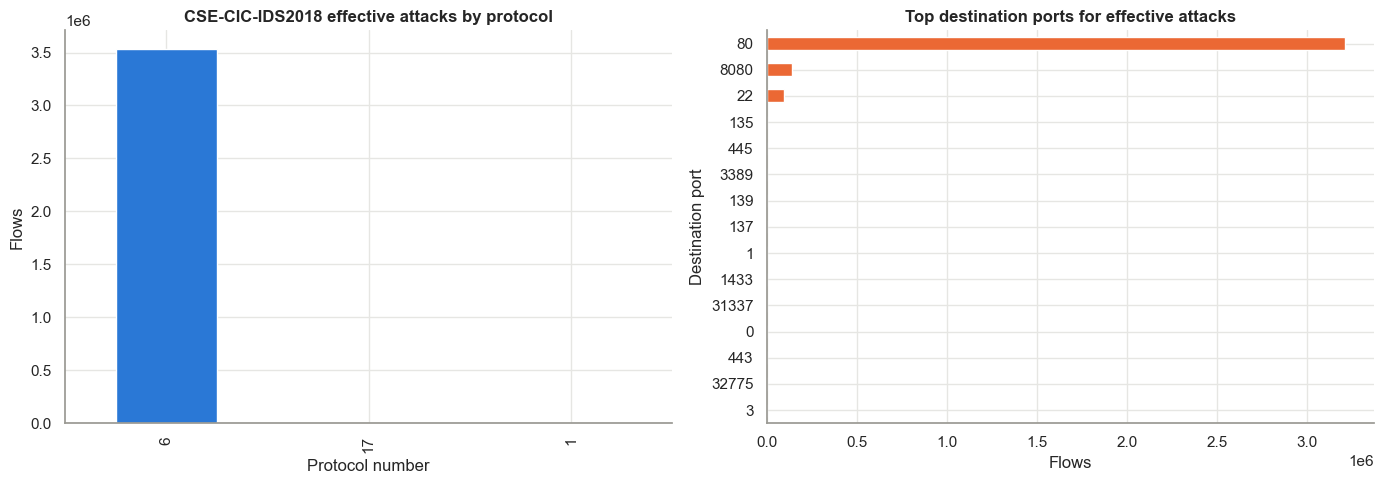

In [4]:
protocol18_table = protocol18.pivot_table(
    index='Label', columns='Protocol', values='flows', aggfunc='sum', fill_value=0
).astype(int)
display(protocol18_table)

top_ports18 = (ports18.sort_values(['Label', 'flows'], ascending=[True, False])
               .groupby('Label').head(3)
               .assign(port_count=lambda d: d['Dst Port'].astype(str) + ' (' + d['flows'].map('{:,}'.format) + ')')
               .groupby('Label')['port_count'].agg(', '.join).rename('top 3 destination ports'))
display(top_ports18.to_frame())

effective_labels18 = [label for label in protocol18.Label.unique()
                      if label != 'BENIGN' and not label.endswith(' - Attempted')]
protocol_plot18 = (protocol18[protocol18.Label.isin(effective_labels18)]
                   .groupby('Protocol').flows.sum().sort_values(ascending=False))
port_plot18 = (ports18[ports18.Label.isin(effective_labels18)]
               .groupby('Dst Port').flows.sum().nlargest(15).sort_values())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
protocol_plot18.plot.bar(ax=axes[0], color=BLUE)
axes[0].set_title('CSE-CIC-IDS2018 effective attacks by protocol')
axes[0].set_xlabel('Protocol number'); axes[0].set_ylabel('Flows')
port_plot18.plot.barh(ax=axes[1], color=ORANGE)
axes[1].set_title('Top destination ports for effective attacks')
axes[1].set_xlabel('Flows'); axes[1].set_ylabel('Destination port')
plt.tight_layout(); plt.show()

#### 2018.2 takeaway

Effective 2018 attacks are dominated by TCP and destination port 80, with smaller protocol and service categories also present. These exact population patterns are useful context, but their concentration may reflect the experimental services rather than universal malicious behavior.


### 2018.3 Sample-based feature summaries and outlier screening

**Why we are doing this.** Quantiles, IQR screening, and log-scaled distributions characterize the range and skew of important continuous variables in the stratified sample.

**Business relevance.** The detector must preserve meaningful attack extremes while handling invalid values safely. This analysis informs transformations and robust preprocessing rather than automatic row deletion.

Quantiles and IQR screening are calculated on the stratified sample. They describe within-label feature behavior but not the natural population mixture.


,min,p0.1,p1,median,p99,p99.9,max,iqr_outliers,iqr_outlier_share
Flow Duration,0.000,1.000,1.0,147643.500,1.190120e+08,1.199949e+08,1.200000e+08,71590,0.189
Total Fwd Packet,0.000,1.000,1.0,5.000,6.400000e+01,1.441356e+05,3.096290e+05,32178,0.085
Total Bwd packets,0.000,0.000,0.0,4.000,3.300000e+01,2.120000e+02,2.390500e+04,32092,0.085
Total Length of Fwd Packet,0.000,0.000,0.0,284.000,1.653168e+04,4.618338e+06,9.908128e+06,37223,0.098
Total Length of Bwd Packet,0.000,0.000,0.0,316.000,1.724990e+04,2.453579e+05,3.477200e+07,46759,0.123
Flow Bytes/s,0.000,0.000,0.0,1615.416,7.115384e+05,4.000000e+06,2.300000e+08,63500,0.168
Flow Packets/s,0.017,0.036,0.1,91.394,2.000000e+06,2.000000e+06,4.000000e+06,68975,0.182
Packet Length Mean,0.000,0.000,0.0,96.000,4.834180e+02,1.175842e+03,1.565740e+04,11937,0.032


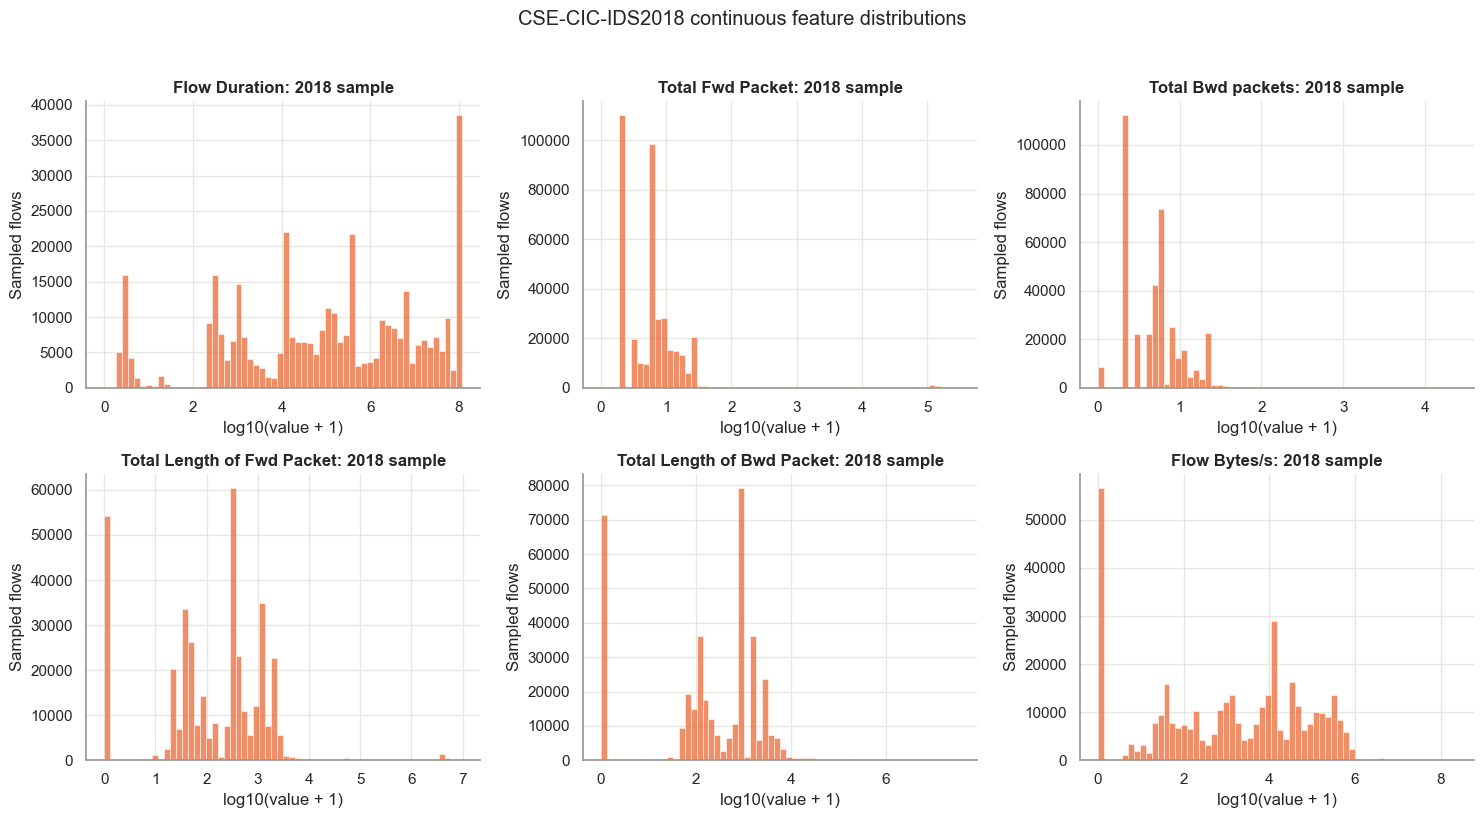

In [5]:
outlier_features18 = [
    'Flow Duration', 'Total Fwd Packet', 'Total Bwd packets',
    'Total Length of Fwd Packet', 'Total Length of Bwd Packet',
    'Flow Bytes/s', 'Flow Packets/s', 'Packet Length Mean'
]
finite18_sample = s18[outlier_features18].replace([np.inf, -np.inf], np.nan)
quantiles18 = finite18_sample.quantile([0, .001, .01, .5, .99, .999, 1]).T
quantiles18.columns = ['min', 'p0.1', 'p1', 'median', 'p99', 'p99.9', 'max']
q1_18, q3_18 = finite18_sample.quantile(.25), finite18_sample.quantile(.75)
iqr18 = q3_18 - q1_18
iqr_count18 = ((finite18_sample.lt(q1_18 - 1.5 * iqr18)) |
               (finite18_sample.gt(q3_18 + 1.5 * iqr18))).sum()
outlier_summary18 = quantiles18.assign(
    iqr_outliers=iqr_count18,
    iqr_outlier_share=iqr_count18 / len(s18),
)
display(outlier_summary18.round(3))

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, column in zip(axes.flat, outlier_features18[:6]):
    values = finite18_sample[column].dropna().clip(lower=0)
    sns.histplot(np.log10(values + 1), bins=60, ax=ax, color=ORANGE)
    ax.set_title(f'{column}: 2018 sample')
    ax.set_xlabel('log10(value + 1)'); ax.set_ylabel('Sampled flows')
fig.suptitle('CSE-CIC-IDS2018 continuous feature distributions', y=1.02)
plt.tight_layout(); plt.show()

#### 2018.3 takeaway

The continuous variables span several orders of magnitude and contain substantial IQR-defined tails. Statistical extremes are expected in network and attack traffic, so log transformation and finite-value handling are preferable to indiscriminate outlier removal.


### 2018.4 Attack timing in the stratified sample

**Why we are doing this.** Attack windows and sampled traffic over time are examined to reveal scheduled bursts and temporal dependence.

**Business relevance.** Recognizing event structure helps prevent optimistic random-split evaluation and clarifies why timestamps and schedule-derived features should not drive detection.

The sample is uniform within labels rather than time intervals, so the chart identifies capture windows but does not estimate full traffic volume over time.


,min,max,count,window minutes
Label,,,,
Botnet Ares,2018-03-02 14:13:34.449756,2018-03-02 19:53:45.988499,20000,340.2
DDoS-HOIC,2018-02-21 18:11:09.831348,2018-02-21 19:05:53.929112,20000,54.7
DDoS-LOIC-HTTP,2018-02-20 14:13:54.662633,2018-02-20 15:16:48.108806,20000,62.9
DoS GoldenEye,2018-02-15 13:27:46.807659,2018-02-15 14:02:59.332681,20000,35.2
DoS Hulk,2018-02-16 17:45:27.841049,2018-02-16 17:58:22.099988,20000,12.9
Infiltration - NMAP Portscan,2018-02-28 14:46:45.793199,2018-03-01 19:37:47.261412,20000,1731.0
SSH-BruteForce,2018-02-14 18:01:50.374537,2018-02-14 19:32:29.744191,20000,90.7
DoS Slowloris,2018-02-15 15:00:12.551313,2018-02-15 15:41:34.311278,8490,41.4
DDoS-LOIC-UDP,2018-02-20 17:14:17.478355,2018-02-21 14:43:16.845708,2527,1289.0


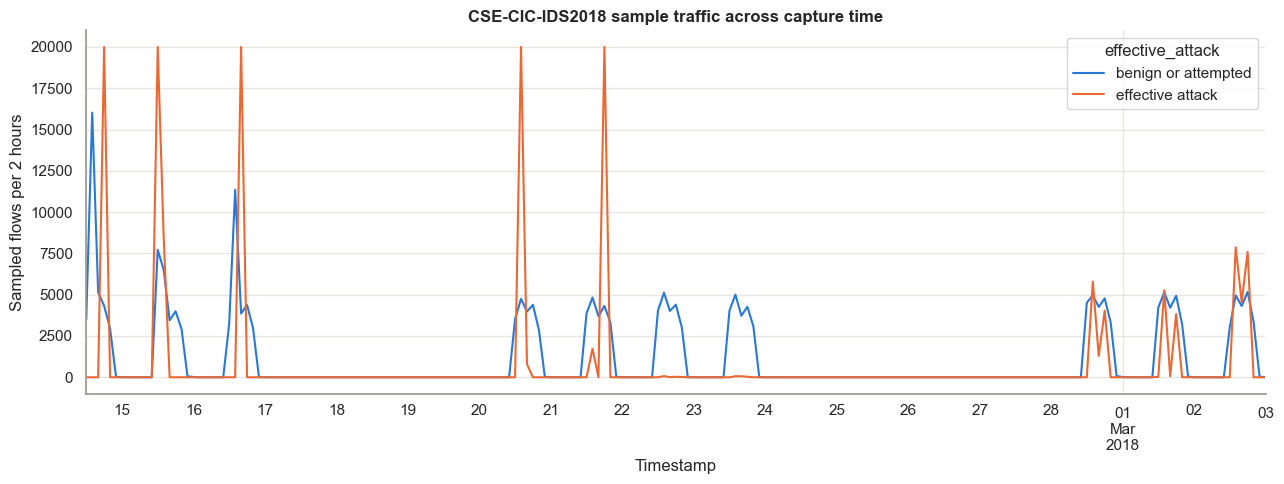

In [6]:
s18['ts'] = pd.to_datetime(s18['Timestamp'], errors='coerce')
s18['effective_attack'] = ~s18.Label.eq('BENIGN') & ~s18.Label.str.endswith(' - Attempted')
timing18 = (s18[s18.effective_attack].groupby('Label').ts
            .agg(['min', 'max', 'count']).sort_values('count', ascending=False))
timing18['window minutes'] = (timing18['max'] - timing18['min']).dt.total_seconds() / 60
display(timing18.round({'window minutes': 1}))

time_plot18 = (s18.set_index('ts').groupby('effective_attack').resample('2h').size()
               .unstack(0, fill_value=0).rename(columns={False: 'benign or attempted', True: 'effective attack'}))
ax = time_plot18.plot(figsize=(13, 5), color=[BLUE, ORANGE])
ax.set_title('CSE-CIC-IDS2018 sample traffic across capture time')
ax.set_xlabel('Timestamp'); ax.set_ylabel('Sampled flows per 2 hours')
plt.tight_layout(); plt.show()

#### 2018.4 takeaway

The sampled labels occur in concentrated capture windows, confirming that neighboring flows are event-dependent. The chart locates events but does not estimate full traffic volume because sampling is uniform within labels rather than time.


### 2018.5 Class-level continuous distributions

**Why we are doing this.** Log-scaled box plots compare key flow behaviors across 2018 attack classes using equal maximum sample sizes per class.

**Business relevance.** Per-class behavior shows which attacks may be detected reliably, where classes overlap, and which environment-sensitive variables require extra scrutiny.

Attempted labels are folded into `BENIGN`, matching the baseline policy. Each class contributes at most 5,000 sampled rows to keep the visualization readable.


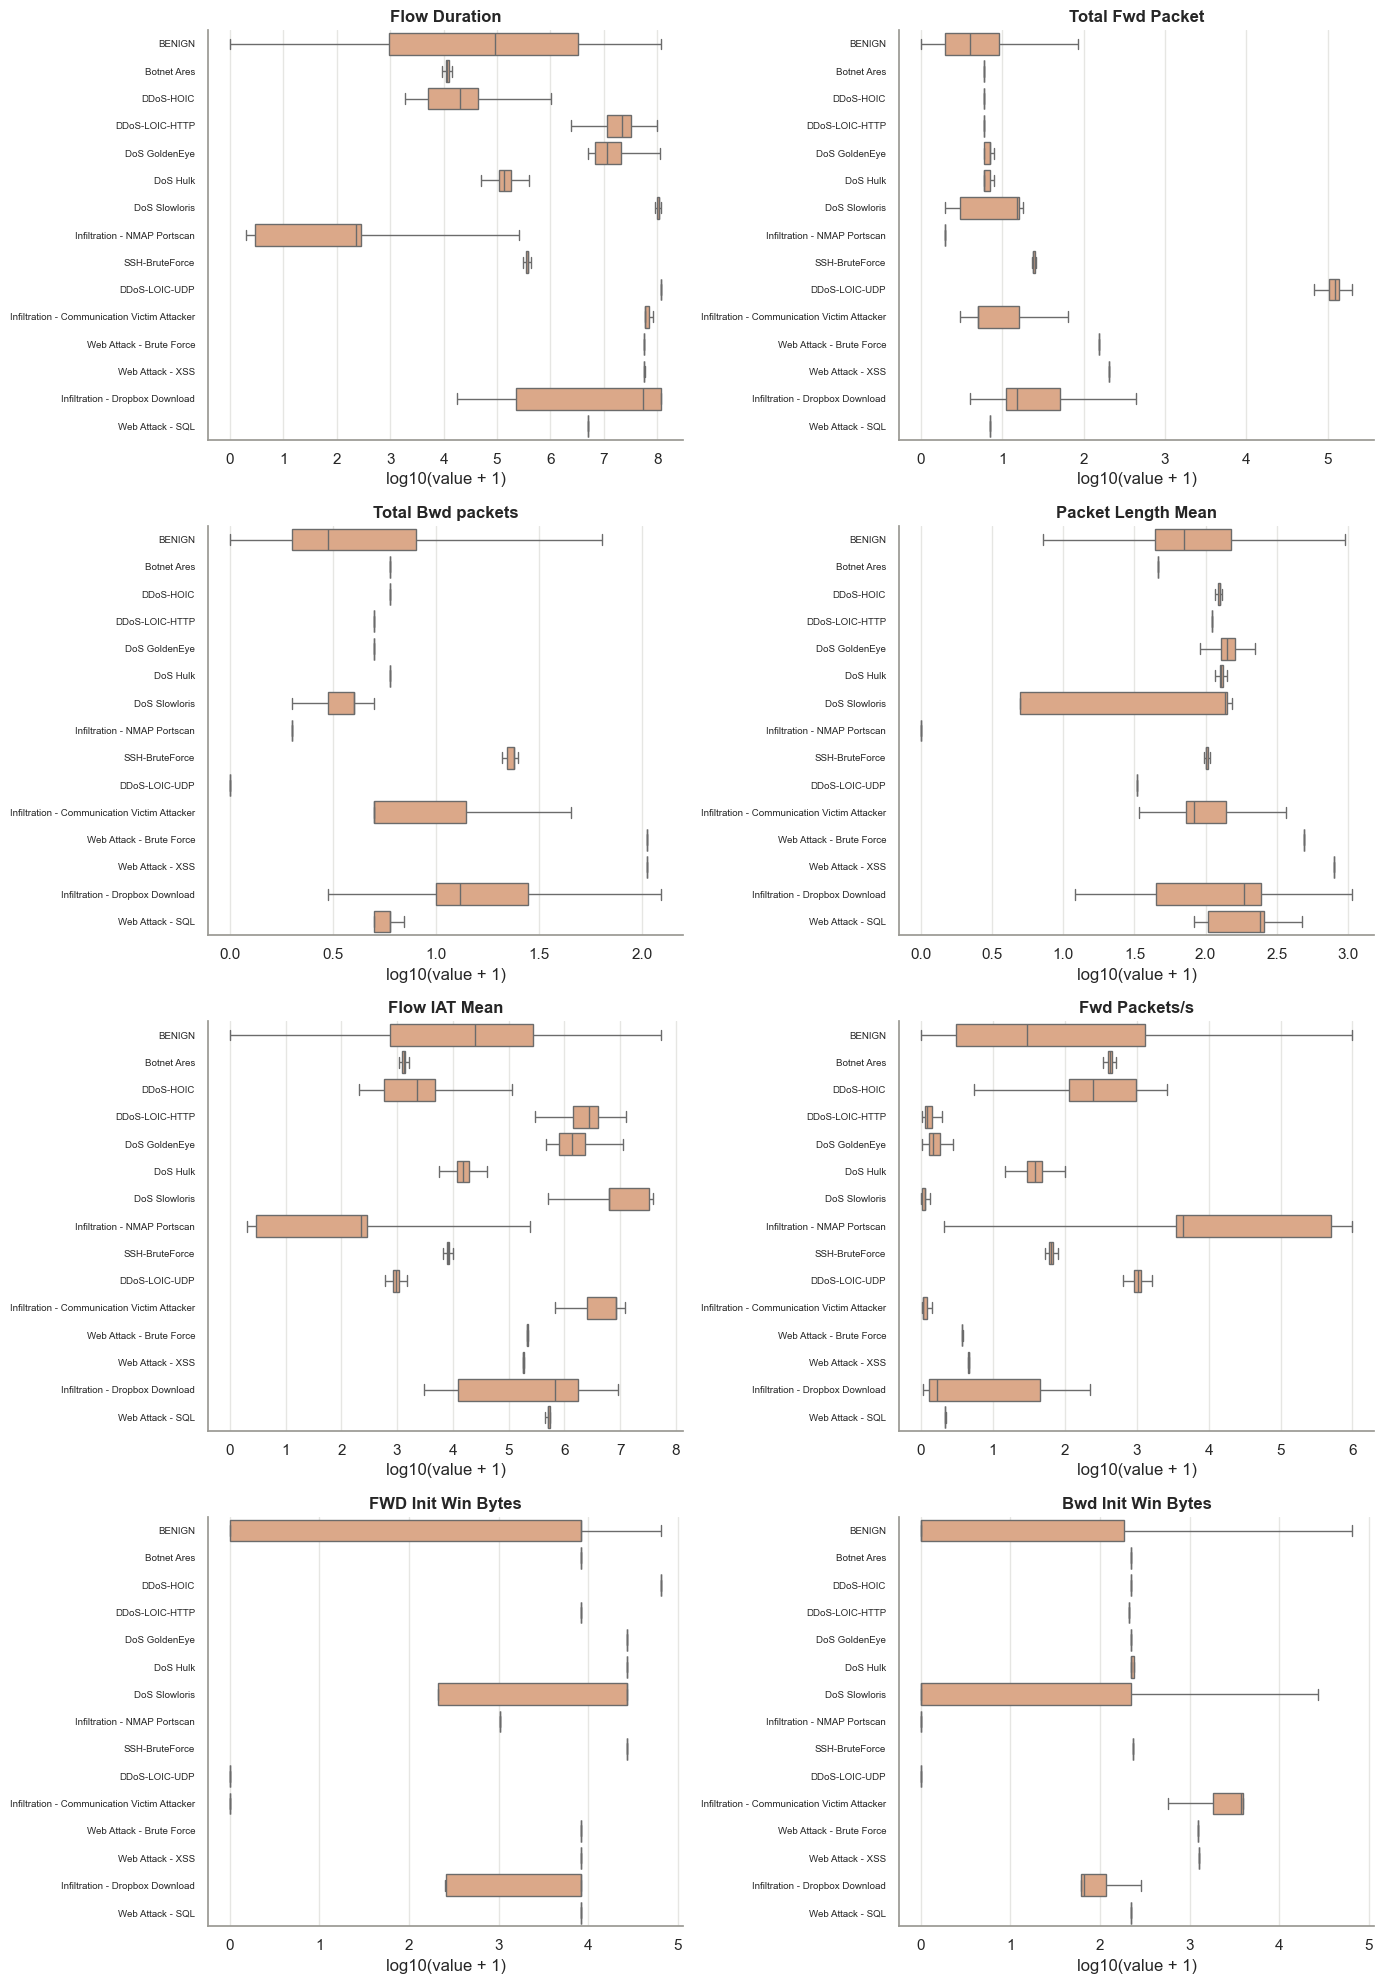

In [7]:
s18['y'] = s18.Label.where(~s18.Label.str.endswith(' - Attempted'), 'BENIGN')
samp18_class = (s18.groupby('y', group_keys=False)
                .apply(lambda group: group.sample(min(len(group), 5_000), random_state=SEED)))
order18 = samp18_class.y.value_counts().index
show18 = ['Flow Duration', 'Total Fwd Packet', 'Total Bwd packets', 'Packet Length Mean',
          'Flow IAT Mean', 'Fwd Packets/s', 'FWD Init Win Bytes', 'Bwd Init Win Bytes']
fig, axes = plt.subplots(4, 2, figsize=(14, 20))
for ax, column in zip(axes.flat, show18):
    plot_frame = samp18_class.assign(value=np.log10(samp18_class[column].clip(lower=0) + 1))
    sns.boxplot(data=plot_frame, y='y', x='value', order=order18,
                showfliers=False, color='#E8A47C', ax=ax)
    ax.set_title(column); ax.set_xlabel('log10(value + 1)'); ax.set_ylabel('')
    ax.tick_params(axis='y', labelsize=7)
plt.tight_layout(); plt.show()

#### 2018.5 takeaway

The class distributions show distinct combinations of duration, packet volume, packet size, timing, and rate, but no single measurement separates all attacks from benign traffic. This supports multivariate models and per-class metrics.


### 2018.6 Correlation and feature redundancy

**Why we are doing this.** Spearman correlation and hierarchical clustering identify features that preserve nearly identical rankings despite heavy skew.

**Business relevance.** A compact feature representation can reduce computation, stabilize explanations, and prevent duplicated measurements from dominating interpretation.

Spearman correlation is calculated on up to 100,000 sampled flows because the variables are heavily skewed.


68 sampled feature pairs have |Spearman correlation| > 0.95


,feature groups
distance threshold (1 - |rho|),
0.0001,75
0.0500,45
0.1000,34
0.2000,28
0.3000,23


absolute Spearman correlation
Fwd URG Flags          URG Flag Count                               1.000000
Packet Length Mean     Average Packet Size                          1.000000
Bwd Packet Length Mean Bwd Segment Size Avg                         1.000000
Fwd Packet Length Mean Fwd Segment Size Avg                         1.000000
Packet Length Std      Packet Length Variance                       1.000000
ICMP Code              ICMP Type                                    0.999999
Fwd Bytes/Bulk Avg     Fwd Packet/Bulk Avg                          0.999950
                       Fwd Bulk Rate Avg                            0.999907
Bwd Bytes/Bulk Avg     Bwd Packet/Bulk Avg                          0.999892
Fwd Packet/Bulk Avg    Fwd Bulk Rate Avg                            0.999867
Bwd Bytes/Bulk Avg     Bwd Bulk Rate Avg                            0.999671
Bwd Packet/Bulk Avg    Bwd Bulk Rate Avg                            0.999518
Idle Mean              Idle Max                                     0.999388
Active Mean            Active Max                                   0.999286
Flow Packets/s         Fwd Packets/s                                0.998911
Active Mean            Active Min                                   0.998383
Flow Packets/s         Flow IAT Mean                                0.997777
Flow IAT Mean          Fwd Packets/s                                0.996820
Active Max             Active Min                                   0.996518
Idle Mean              Idle Min                                     0.996037
Bwd IAT Total          Bwd IAT Max                                  0.993849
Idle Max               Idle Min                                     0.993371
Bwd IAT Mean           Bwd IAT Max                                  0.993348
Bwd Segment Size Avg   Subflow Bwd Bytes                            0.989289
Bwd Packet Length Mean Subflow Bwd Bytes                            0.989289
Bwd IAT Total          Bwd IAT Mean                                 0.988654
Fwd IAT Total          Fwd IAT Max                                  0.988253
CWR Flag Count         ECE Flag Count                               0.988152
Fwd Packet Length Mean Subflow Fwd Bytes                            0.988095
Fwd Segment Size Avg   Subflow Fwd Bytes                            0.988095

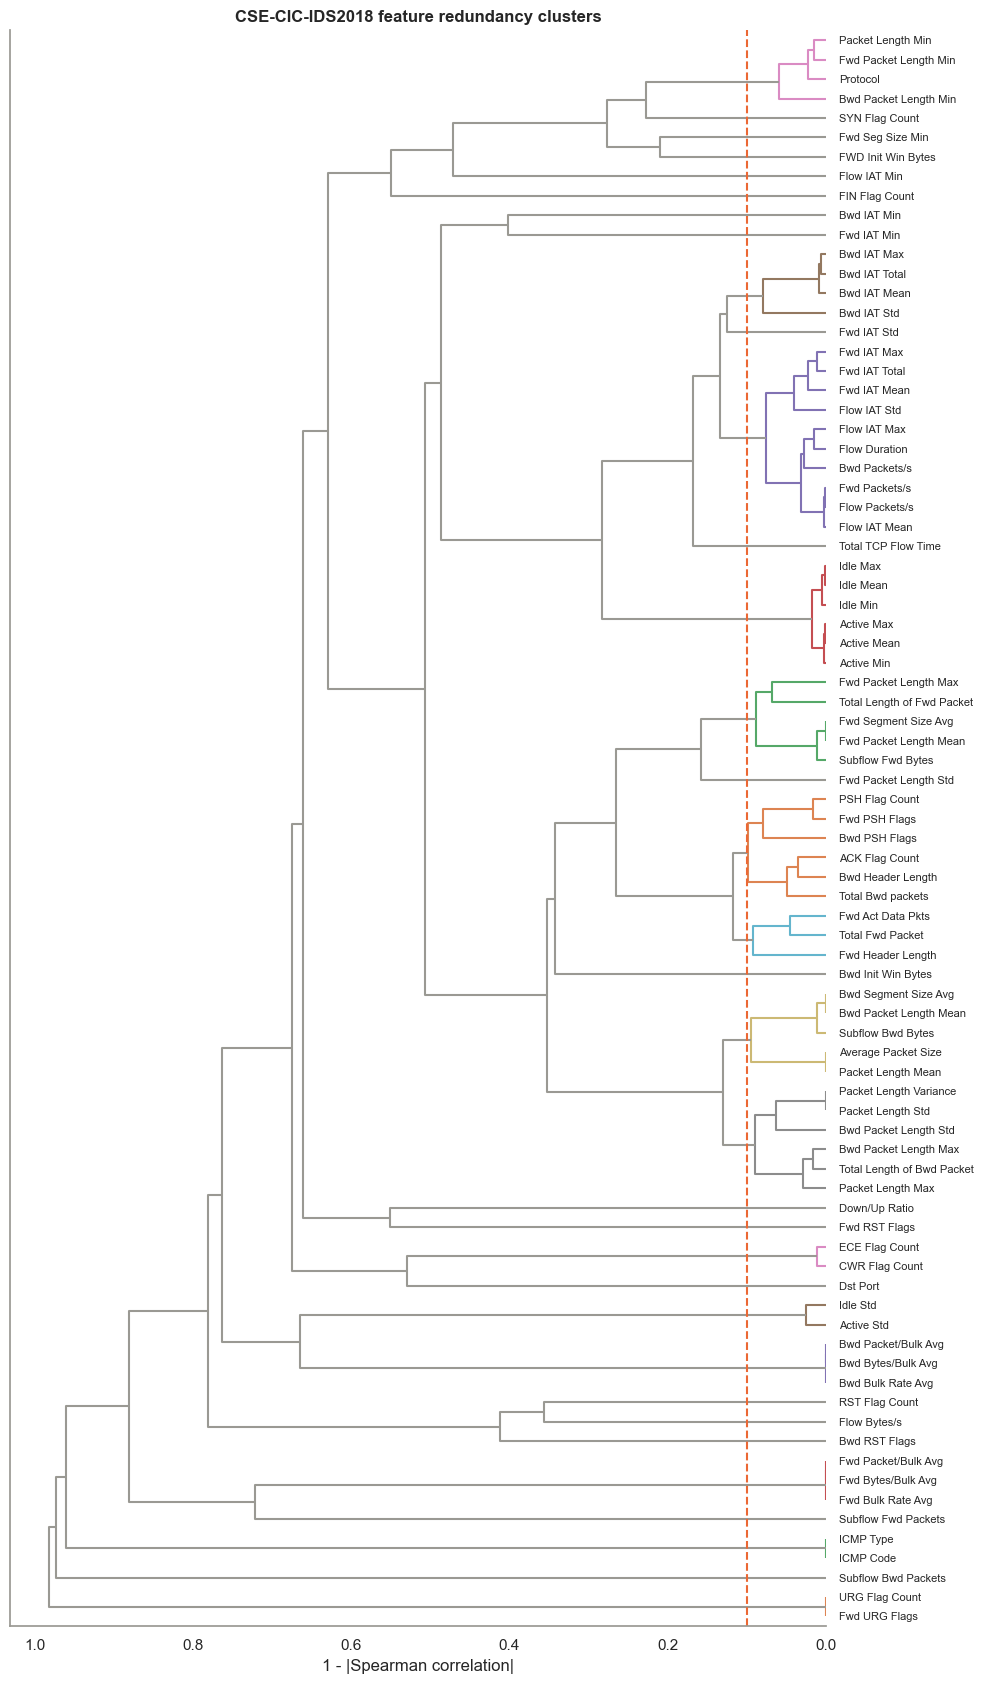

In [8]:
corr_sample18 = s18[FEATURES].sample(min(100_000, len(s18)), random_state=SEED)
rho18 = corr_sample18.rank().corr().abs().fillna(0)
upper18 = rho18.where(np.triu(np.ones(rho18.shape, dtype=bool), 1)).stack()
high18 = upper18[upper18 > 0.95].sort_values(ascending=False)

distance18 = 1 - rho18.values
np.fill_diagonal(distance18, 0)
distance18 = (distance18 + distance18.T) / 2
linkage18 = linkage(squareform(distance18, checks=False), method='average')
clusters18 = pd.Series({threshold: len(set(fcluster(linkage18, threshold, 'distance')))
                        for threshold in [0.0001, 0.05, 0.1, 0.2, 0.3]},
                       name='feature groups').rename_axis('distance threshold (1 - |rho|)')
print(f'{len(high18)} sampled feature pairs have |Spearman correlation| > 0.95')
display(clusters18.to_frame())
display(high18.head(30).rename('absolute Spearman correlation').to_frame())

fig, ax = plt.subplots(figsize=(10, 17))
dendrogram(linkage18, labels=FEATURES, orientation='left', color_threshold=0.1,
           above_threshold_color=GREY, leaf_font_size=8, ax=ax)
ax.axvline(0.1, color=ORANGE, linestyle='--')
ax.set_xlabel('1 - |Spearman correlation|')
ax.set_title('CSE-CIC-IDS2018 feature redundancy clusters')
ax.grid(False); plt.tight_layout(); plt.show()

#### 2018.6 takeaway

The sample contains 68 feature pairs with absolute Spearman correlation above 0.95 and forms 34 groups at the 0.90 threshold. Substantial redundancy supports testing compact representatives or regularization before interpreting model importance.


### 2018.7 PCA of the stratified sample

**Why we are doing this.** PCA projects the standardized, transformed feature space into two dimensions to inspect multivariate class structure without fitting a classifier.

**Business relevance.** Visible separation supports the feasibility of automated detection, while overlap highlights likely errors and possible testbed-specific clusters that require supervised cross-network validation.

PCA is used only as an exploratory view of class structure. It is not used as the final detector.


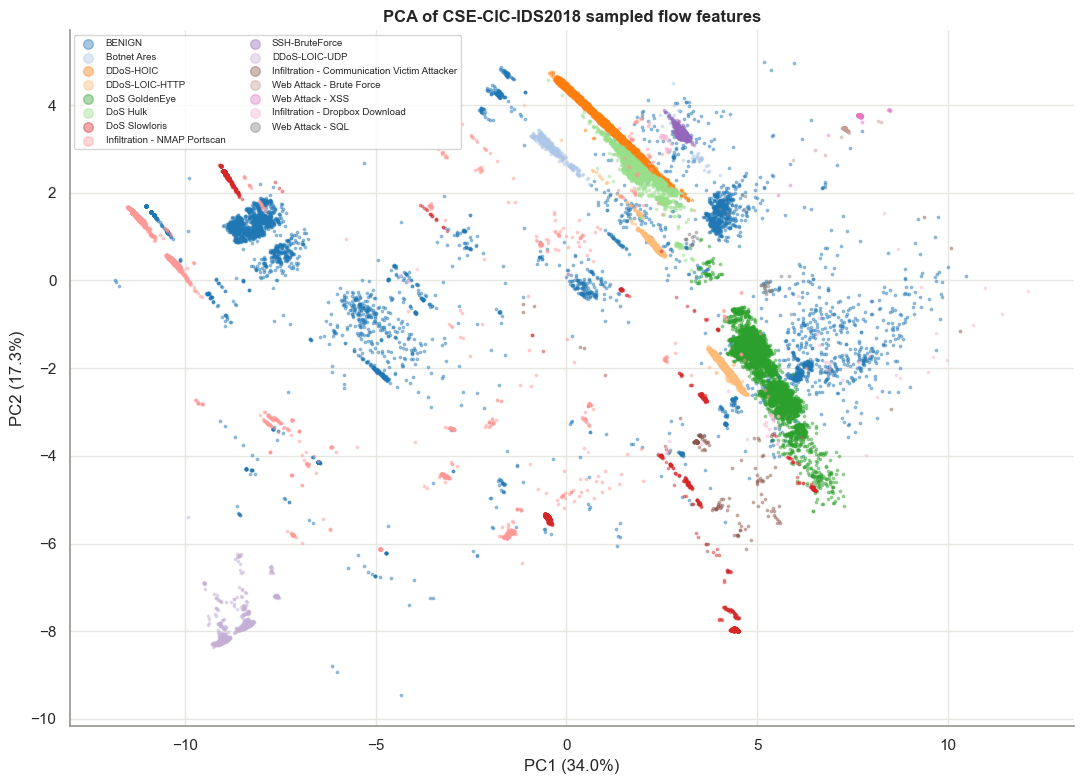

In [9]:
pca_input18 = samp18_class[FEATURES].replace([np.inf, -np.inf], np.nan).fillna(0)
scaled18 = StandardScaler().fit_transform(signed_log(pca_input18))
pca18 = PCA(2, random_state=SEED).fit(scaled18)
projection18 = pca18.transform(scaled18)

fig, ax = plt.subplots(figsize=(11, 8))
palette18 = sns.color_palette('tab20', len(order18))
for label, color in zip(order18, palette18):
    mask = (samp18_class.y == label).values
    ax.scatter(projection18[mask, 0], projection18[mask, 1], s=3, alpha=0.4,
               color=color, label=label)
ax.set_xlabel(f'PC1 ({pca18.explained_variance_ratio_[0]:.1%})')
ax.set_ylabel(f'PC2 ({pca18.explained_variance_ratio_[1]:.1%})')
ax.set_title('PCA of CSE-CIC-IDS2018 sampled flow features')
ax.legend(markerscale=4, fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

#### 2018.7 takeaway

The first two principal components explain approximately 51.3% of transformed-feature variation (34.0% and 17.3%). Several classes form visible structures, but overlap and the unshown variation mean PCA is exploratory evidence—not a classifier score or a generalization result.


### 2018.8 Extended EDA findings

The summary below is generated from the full-data audit and sample-based analysis objects.

In [10]:
lab18 = (protocol18.groupby('Label').flows.sum().sort_values(ascending=False).to_frame())
lab18['share'] = lab18.flows / lab18.flows.sum()
top_protocol18 = int(protocol18.groupby('Protocol').flows.sum().idxmax())
top_attack_port18 = int(ports18[ports18.Label.isin(effective_labels18)].groupby('Dst Port').flows.sum().idxmax())
most_common_attack18 = str(lab18.drop(index='BENIGN', errors='ignore').index[0])

eda2018_findings = pd.DataFrame([
    ('Coverage', f"{quality18['total_rows']:,} rows across {len(file_rows18)} files were scanned."),
    ('Schema', f'{len(cols18)} columns; matches CICIDS2017: {bool(len(cols17)) and list(cols17) == list(cols18)}.'),
    ('Missing values', f'{int(missing18.sum()):,} missing cells across the full dataset.'),
    ('Infinite values', f'{int(infinite18.sum()):,} infinite numeric values across the full dataset.'),
    ('Anomalies', ', '.join(f'{name}: {int(value):,}' for name, value in anomalies18.items())),
    ('Class balance', f"BENIGN represents {lab18.loc['BENIGN', 'share']:.2%}; largest attack label is {most_common_attack18}."),
    ('Protocol', f'Most common protocol is {top_protocol18}.'),
    ('Attack destination port', f'Most common effective-attack destination port is {top_attack_port18}.'),
    ('Sample outliers', f'IQR outlier shares range from {outlier_summary18.iqr_outlier_share.min():.2%} to {outlier_summary18.iqr_outlier_share.max():.2%}.'),
    ('Redundancy', f'{len(FEATURES)} features form {int(clusters18.loc[0.1])} groups at |Spearman correlation| >= 0.9.'),
    ('PCA', f'The first two components explain {pca18.explained_variance_ratio_.sum():.2%} of sampled transformed-feature variance.'),
], columns=['Area', '2018 finding'])
display(eda2018_findings.style.hide(axis='index').set_properties(**{'text-align': 'left'}))

Area,2018 finding
Coverage,"63,195,145 rows across 10 files were scanned."
Schema,91 columns; matches CICIDS2017: True.
Missing values,0 missing cells across the full dataset.
Infinite values,114 infinite numeric values across the full dataset.
Anomalies,"zero or negative duration: 57, negative forward header length: 10,039, negative backward header length: 17,509, infinite flow byte rate: 57, infinite flow packet rate: 57"
Class balance,BENIGN represents 93.92%; largest attack label is DoS Hulk.
Protocol,Most common protocol is 6.
Attack destination port,Most common effective-attack destination port is 80.
Sample outliers,IQR outlier shares range from 3.15% to 18.89%.
Redundancy,82 features form 34 groups at |Spearman correlation| >= 0.9.
